## Упражнения

In [1]:
# Imports
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import cv2
np.random.seed(0) # for reproducibility

### Упражнение № 1
Это упражнение относится к [Примеру 1](#example-1-static-one-dimensional-data).
1. Выберите значение для оценочной дисперсии модели `Q_est`, которое больше оценочной дисперсии измерения `R_est`.
2. Повторите анализ Примера 1 для этого нового значения.
3. Сходится ли оценка KF?
4. Почему изменились оценки? Они выглядят более шумными, чем раньше? Почему?

In [2]:
def kalman_1d(x, P, measurement, R_est, Q_est):

    # Prediction
    x_pred = x
    P_pred = P + Q_est

    # Update
    K = P_pred / (P_pred + R_est)

    x_est = x_pred + K * (measurement - x_pred)
    P_est = (1 - K) * P_pred

    return x_est, P_est

In [3]:
def plot_1d_comparison(measurements_made, estimate, true_value, axis):
    axis.plot(measurements_made,'k+',label='measurements',alpha=0.3)
    axis.plot(estimate,'-',label='KF estimate')
    if not isinstance(true_value, (list, tuple, np.ndarray)):
        # plot line for a constant value
        axis.axhline(true_value,color='r',label='true value', alpha=0.5)
    else:
        # for a list, tuple or array, plot the points
        axis.plot(true_value,color='r',label='true value', alpha=0.5)
    axis.legend(loc = 'lower right')
    axis.set_title('Estimated position vs. time step')
    axis.set_xlabel('Time')
    axis.set_ylabel('$x_t$')

def plot_1d_error(estimated_error, lower_limit, upper_limit, axis):
    # lower_limit and upper_limit are the lower and upper limits of the vertical axis
    axis.plot(estimated_error, label='KF estimate for $P$')
    axis.legend(loc = 'upper right')
    axis.set_title('Estimated error vs. time step')
    axis.set_xlabel('Time')
    axis.set_ylabel('$P_t$')
    plt.setp(axis,'ylim',[lower_limit, upper_limit])

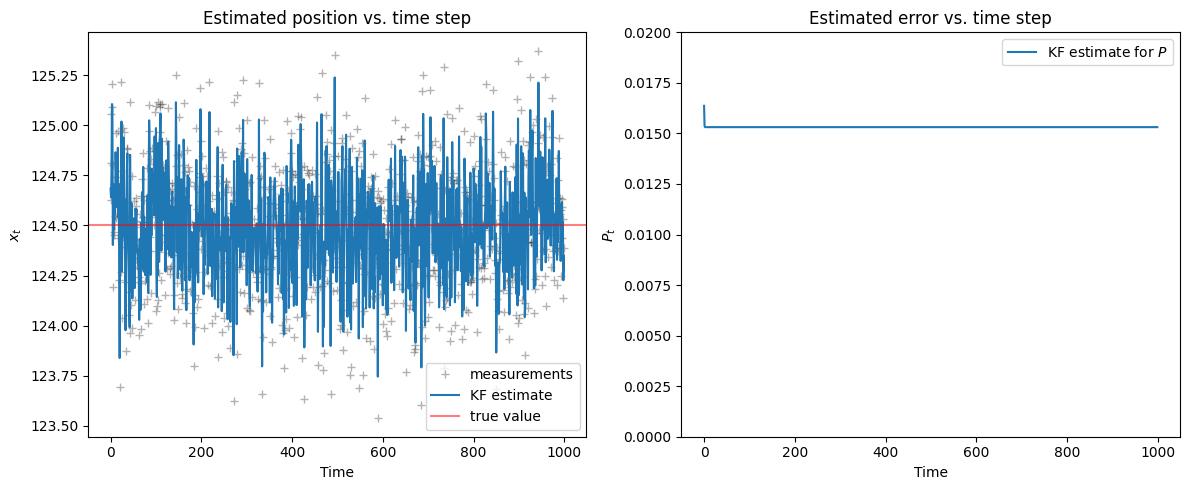

In [4]:
mu = 124.5 # истинное положение
R = 0.1    # стандартное отклонение фактических измерений

n_measurements = 1000 # кол-во измерений
Z = np.random.normal(mu, np.sqrt(R), size=n_measurements)

# Q_est > R_est
Q_est = 0.05
R_est = 0.02

# начальные условия
x = 123.0
P = 0.04


KF_estimate=[] # прогнозы положений
KF_error=[] # ошибки
for z in Z:
    x, P = kalman_1d(x, P, z, R_est, Q_est)
    KF_estimate.append(x)
    KF_error.append(P)


fig, axes = plt.subplots(1,2, figsize=(12, 5))
plot_1d_comparison(Z, KF_estimate, mu, axes[0])
plot_1d_error(KF_error, 0, 0.02, axes[1])
plt.tight_layout();

Значение Q_est, превышающее R_est, указывает на то, что оценка следующего положения будет больше полагаться на новое измерение, а не на прошлую оценку. Именно поэтому фильтр выглядит более шумным, чем при меньшем Q_est. Оценка KF сходитя к значению 0.0153

### Упражнение №2

Это упражнение относится к [Примеру 2](#example-2-dynamic-one-dimensional-data).

В случае, который мы рассмотрели выше, оценка KF была близка к измерениям, и оба отличались от истинного значения.
Изменяйте параметры алгоритма, пока не найдете некоторые комбинации, которые достигают следующего:

1. Измерения, оценка KF и истинное значение все близки.
2. Измерения, оценка KF и истинное значение все заметно отличаются.
3. Измерения близки к истинному значению, но оценка KF отличается.

Обсудите свои выводы.

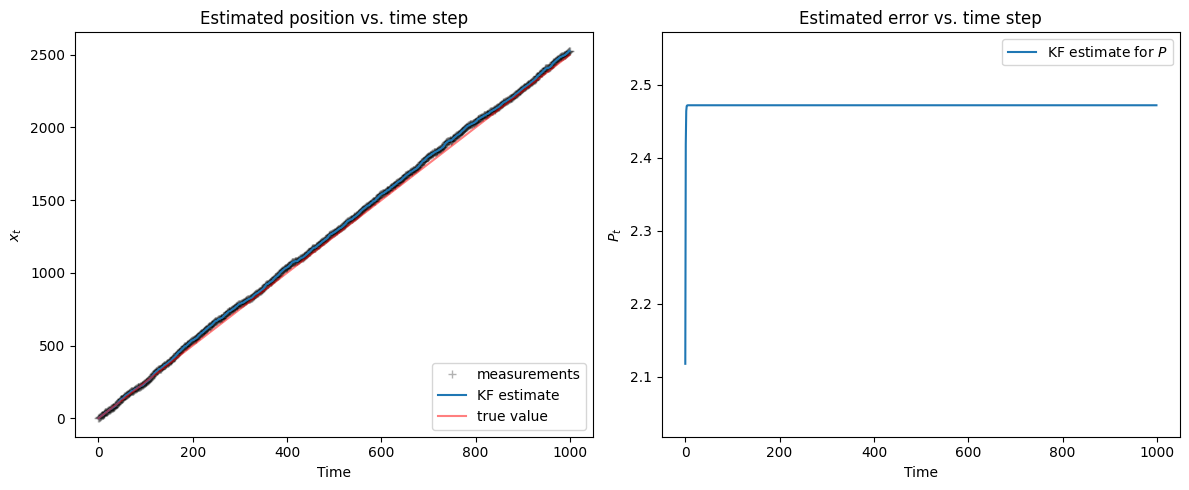

In [5]:
# начальные параметры
v0 = 2.5 # скорость
x0 = 0.0 # начальная позиция
R = 4.0

n_measurements = 1000
Zv = np.zeros(n_measurements) # скорость измерений
Zx = np.zeros(n_measurements) # положение измерений
for t in range(0, n_measurements-1):
    Zv[t] = np.random.normal(v0, np.sqrt(R))
    Zx[t+1] = Zx[t] + Zv[t] * 1 # delta_t = 1

# истинная траектория
Xt = np.zeros(n_measurements)
for t in range(0, n_measurements):
    Xt[t]= x0 + v0*t

x = 0
P = 0.5
Q_est = 4 # дисперсия шума процесса
R_est = 4 # дисперсия шума измерений
KF_estimate = [] # прогнозы положений
KF_error = [] # ошибки

for z in Zx:
    x, P = kalman_1d(x, P, z, R_est, Q_est)
    KF_estimate.append(x)
    KF_error.append(P)

fig, axes = plt.subplots(1,2, figsize=(12, 5))
plot_1d_comparison(Zx, KF_estimate, Xt, axes[0])
plot_1d_error(KF_error, min(KF_error)-0.1, max(KF_error)+0.1, axes[1])
plt.tight_layout();

Если сделать скорость 2.5, то влияние шума измерений будет не настолько большим (стандартное отклонение: sqrt(4)=2), поэтому измерения, фильтр и истинная траектория будут хорошо совпадать.

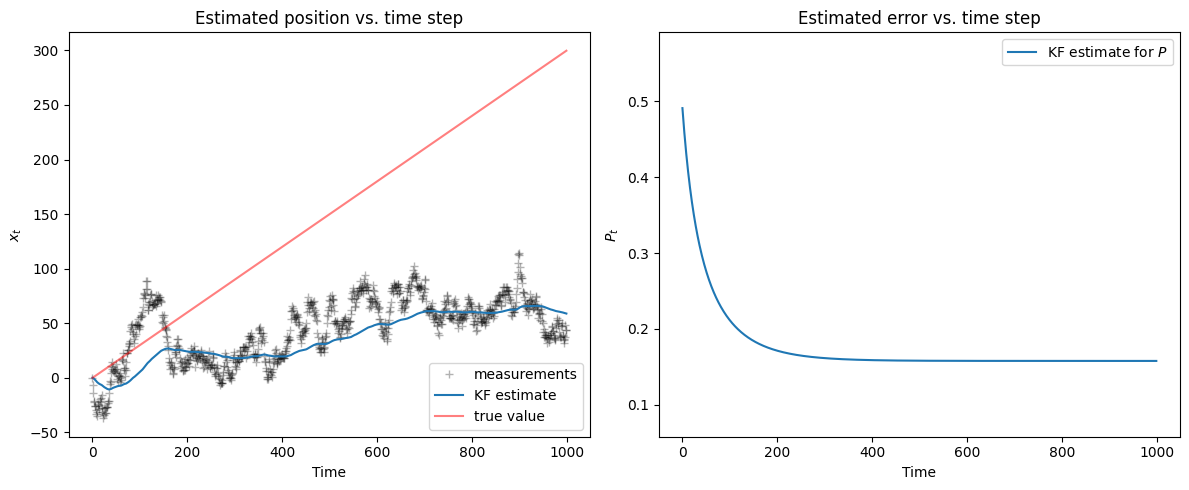

In [6]:
# начальные параметры
v0 = 0.3 # скорость
x0 = 0.0 # начальная позиция
R = 25.0

n_measurements = 1000
Zv = np.zeros(n_measurements) # скорость измерений
Zx = np.zeros(n_measurements) # положение измерений
for t in range(0, n_measurements-1):
    Zv[t] = np.random.normal(v0, np.sqrt(R))
    Zx[t+1] = Zx[t] + Zv[t] * 1 # delta_t = 1

# истинная траектория
Xt = np.zeros(n_measurements)
for t in range(0, n_measurements):
    Xt[t]= x0 + v0*t

x = 0
P = 0.5
Q_est = 0.001 # дисперсия шума процесса
R_est = 25.0 # дисперсия шума измерений
KF_estimate = [] # прогнозы положений
KF_error = [] # ошибки

for z in Zx:
    x, P = kalman_1d(x, P, z, R_est, Q_est)
    KF_estimate.append(x)
    KF_error.append(P)

fig, axes = plt.subplots(1,2, figsize=(12, 5))
plot_1d_comparison(Zx, KF_estimate, Xt, axes[0])
plot_1d_error(KF_error, min(KF_error)-0.1, max(KF_error)+0.1, axes[1])
plt.tight_layout();

Если практически исключить шум процесса и сделать большой шум измерений, то фильтр будет очень сильно сглаживать измерения, больше полагаясь на прошлые отфильтрованные значения.

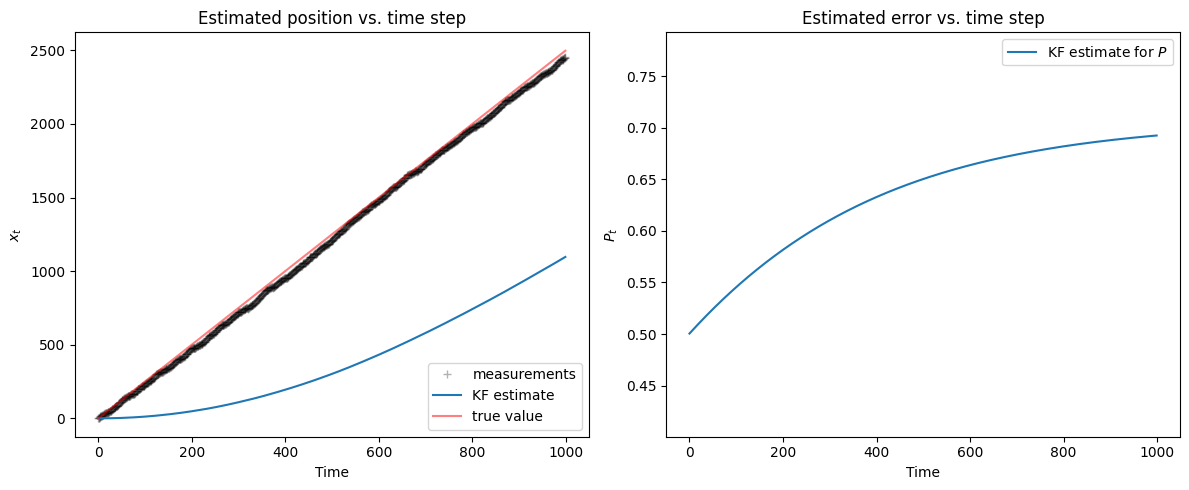

In [7]:
# начальные параметры
v0 = 2.5          # скорость
x0 = 0.0          # начальная позиция
R = 4.0           # дисперсия шума измерений (при генерации)

n_measurements = 1000
Zv = np.zeros(n_measurements)
Zx = np.zeros(n_measurements)
for t in range(0, n_measurements-1):
    Zv[t] = np.random.normal(v0, np.sqrt(R))
    Zx[t+1] = Zx[t] + Zv[t] * 1

# истинная траектория
Xt = np.zeros(n_measurements)
for t in range(0, n_measurements):
    Xt[t] = x0 + v0 * t

# Параметры фильтра (изменены)
x = 0.0
P = 0.5
Q_est = 0.001
R_est = 500.0

KF_estimate = []
KF_error = []

for z in Zx:
    x, P = kalman_1d(x, P, z, R_est, Q_est)
    KF_estimate.append(x)
    KF_error.append(P)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_1d_comparison(Zx, KF_estimate, Xt, axes[0])
plot_1d_error(KF_error, min(KF_error)-0.1, max(KF_error)+0.1, axes[1])
plt.tight_layout()

Если практически исключить шум процесса и сделать большой шум измерений, а при генерации измерений сделать маленький шум измерений, то фильтр будет очень сильно полагаться на прошлую оценку. Таким образом, фильтр будет сильно отклоняться от измерений и истинной траектории.

### Упражнение №3

Это упражнение относится к [Примеру 3](#example-3-dynamic-two-dimensional-data).

В исходном примере мы использовали и Положение, и Скорость (модель PV) в векторе состояния, т. е. $\boldsymbol{x} = \begin{bmatrix} x & y & \dot x & \dot y \end{bmatrix}^T$.

Что произойдет, если мы используем только Положение (модель P) для описания состояния? В конце концов, наши измерения предоставляют только положение. Действительно ли нам нужно включать скорость?

1. Перепишите алгоритм выше для модели P.

**💡 Подсказка:** каков размер вектора состояния в этом случае? Каковы размерности матриц, характеризующих систему?

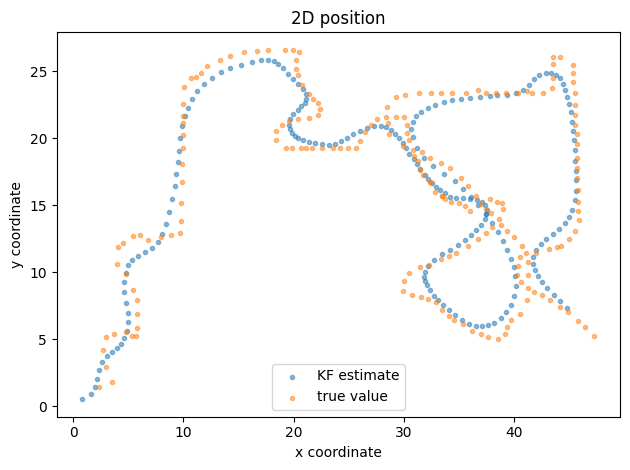

In [8]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

# модель P учитывает только позицию, без скорости
kalman = cv2.KalmanFilter(2, 2, 0)

q = 1   # шум модели
r = 20  # шум измерений

kalman.measurementMatrix = np.array([[1,0], [0,1]], dtype=np.float32) # H
kalman.transitionMatrix = np.array([[1,0], [0,1]], dtype=np.float32) # F
kalman.processNoiseCov = np.array([[1,0], [0,1]], dtype=np.float32) * q # Q
kalman.measurementNoiseCov = np.array([[1,0], [0,1]], dtype=np.float32) * r # R

kalman.statePost = np.zeros((2, 1), dtype=np.float32)
kalman.errorCovPost = np.array([[1,0], [0,1]], dtype=np.float32) * 10.0

xy_motion = pd.read_csv('https://zenodo.org/records/10951538/files/kf_ts1.csv?download=1',
                        header=None).values.astype('float32')

KF_estimate_xy = []
for i in xy_motion:
    pred = kalman.predict()
    measurement = np.array([[i[0]], [i[1]]], dtype=np.float32)
    kalman.correct(measurement)
    x_est = kalman.statePost[0, 0]
    y_est = kalman.statePost[1, 0]
    KF_estimate_xy.append((x_est, y_est))


x_est, y_est = zip(*KF_estimate_xy)
x_true, y_true = zip(*xy_motion)

plt.scatter(x_est, y_est, marker= '.', label = 'KF estimate', alpha = 0.5)
plt.scatter(x_true, y_true,marker= '.', label = 'true value', alpha = 0.5)
plt.legend(loc = 'lower center')
plt.title('2D position')
plt.xlabel('x coordinate')
plt.ylabel('y coordinate')
plt.tight_layout();

Если для описания состояния использовать только положение, то фильтр отработает хуже (при тех же значениях q и r). Если же уменьшить шум измерений до 1, то фильтр будет хорошо повторять измерения (код ниже).

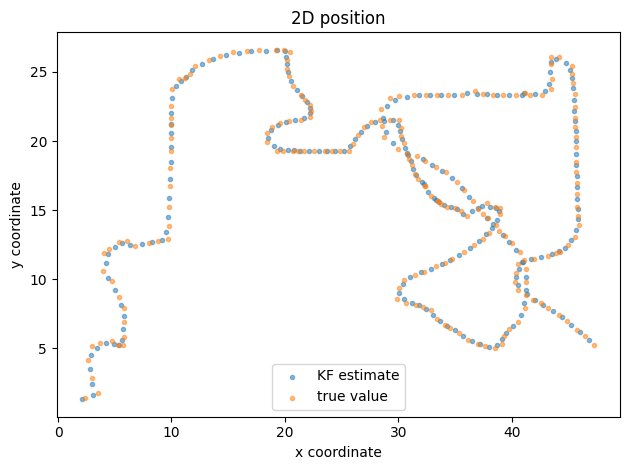

In [9]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

# модель P учитывает только позицию, без скорости
kalman = cv2.KalmanFilter(2, 2, 0)

q = 1   # шум модели
r = 1  # шум измерений

kalman.measurementMatrix = np.array([[1,0], [0,1]], dtype=np.float32) # H
kalman.transitionMatrix = np.array([[1,0], [0,1]], dtype=np.float32) # F
kalman.processNoiseCov = np.array([[1,0], [0,1]], dtype=np.float32) * q # Q
kalman.measurementNoiseCov = np.array([[1,0], [0,1]], dtype=np.float32) * r # R

kalman.statePost = np.zeros((2, 1), dtype=np.float32)
kalman.errorCovPost = np.array([[1,0], [0,1]], dtype=np.float32) * 10.0

xy_motion = pd.read_csv('https://zenodo.org/records/10951538/files/kf_ts1.csv?download=1',
                        header=None).values.astype('float32')

KF_estimate_xy = []
for i in xy_motion:
    pred = kalman.predict()
    measurement = np.array([[i[0]], [i[1]]], dtype=np.float32)
    kalman.correct(measurement)
    x_est = kalman.statePost[0, 0]
    y_est = kalman.statePost[1, 0]
    KF_estimate_xy.append((x_est, y_est))


x_est, y_est = zip(*KF_estimate_xy)
x_true, y_true = zip(*xy_motion)

plt.scatter(x_est, y_est, marker= '.', label = 'KF estimate', alpha = 0.5)
plt.scatter(x_true, y_true,marker= '.', label = 'true value', alpha = 0.5)
plt.legend(loc = 'lower center')
plt.title('2D position')
plt.xlabel('x coordinate')
plt.ylabel('y coordinate')
plt.tight_layout();